# 03 — Dummy, Logistic Regression & kNN

Tune every choice on the fixed 54k/6k train/validation split. Final fits use 60k images. Test data is accessed only by `final_test_run()`.

Saved validation and test JSONs are reused on subsequent runs. This lets Restart & Run All reproduce figures and analysis without evaluating the test set again. A cached test result must match the selected validation parameters. To investigate a genuine bug requiring another test run, document the reason in decisions.md first; preserve the audit log.

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd() if (pathlib.Path.cwd() / "src").exists() else pathlib.Path.cwd().parent
sys.path.insert(0, str(ROOT))

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from src import config
from src.experiment import tune_on_val, final_test_run
from src.models_linear import make_dummy, make_logreg, make_knn, DUMMY_GRID, LOGREG_GRID, KNN_GRID
from src.utils import save_fig, set_seed

set_seed()
factories = {"dummy": make_dummy, "logreg": make_logreg}
grids = {"dummy": DUMMY_GRID, "logreg": LOGREG_GRID}
validation = {}
test_results = {}


## Validation first

⏱ LR validation takes about 3–5 minutes on this machine when caches are missing. LR uses StandardScaler inside its Pipeline and an L2-regularised multinomial classifier. All C values are scored on validation; the highest accuracy wins, with exact ties resolved by grid order.

For class c, the model computes a score `w_c · x + b_c`, then softmax converts the ten scores into probabilities. Training minimises cross-entropy (negative log probability of the correct class) plus the weight penalty. Smaller C means stronger regularisation: it discourages large weights and can reduce overfitting. The iteration cap is 5,000 because two initial large-C pixel fits reached 1,000 iterations.

In [2]:
for name, make_fn in factories.items():
    for kind in ("pixels", "hog"):
        experiment = f"{name}_{kind}"
        path = config.METRICS_DIR / f"{experiment}_val.json"
        if not path.exists():
            tune_on_val(name, make_fn, grids[name], kind)
        result = json.loads(path.read_text())
        assert result["grid"] == grids[name]
        validation[experiment] = result
        print(experiment, result["best_params"], "val accuracy:", result["best_val_acc"])


dummy_pixels {} val accuracy: 0.1
dummy_hog {} val accuracy: 0.1
logreg_pixels {'C': 0.01} val accuracy: 0.8642
logreg_hog {'C': 0.01} val accuracy: 0.8927


saved results/figures/linear_logreg_val_curve_pixels.png


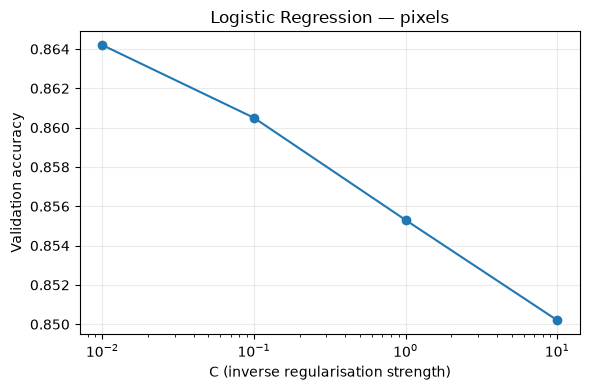

saved results/figures/linear_logreg_val_curve_hog.png


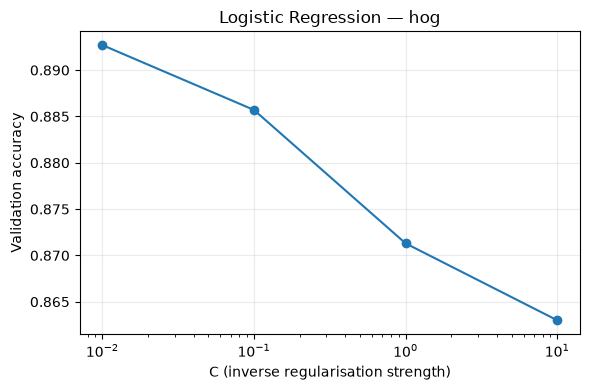

In [3]:
for kind in ("pixels", "hog"):
    result = validation[f"logreg_{kind}"]
    rows = result["rows"]
    fig, ax = plt.subplots(figsize=(6, 4))
    ax.semilogx([row["params"]["C"] for row in rows], [row["val_acc"] for row in rows], "o-")
    ax.set(xlabel="C (inverse regularisation strength)", ylabel="Validation accuracy",
           title=f"Logistic Regression — {kind}")
    ax.grid(alpha=0.25)
    fig.tight_layout()
    save_fig(fig, f"linear_logreg_val_curve_{kind}")
    plt.show()


## Final evaluation — one recorded run per experiment

⏱ LR final fits take about 15–30 seconds per feature set. Each missing result is produced once through `final_test_run`; subsequent notebook runs read only stored metrics. Dummy predicts the most frequent training class. The balanced data makes that class 0 under sklearn's tie rule, yielding 10% accuracy for either feature set.

In [4]:
for name, make_fn in factories.items():
    for kind in ("pixels", "hog"):
        experiment = f"{name}_{kind}"
        params = validation[experiment]["best_params"]
        path = config.METRICS_DIR / f"{experiment}_test.json"
        if path.exists():
            result = json.loads(path.read_text())
            if result["best_params"] != params:
                raise RuntimeError(f"{experiment}: saved test parameters differ; investigate and log any rerun first.")
        else:
            if config.TEST_LOG_PATH.exists() and experiment in pd.read_csv(config.TEST_LOG_PATH)["experiment"].values:
                raise RuntimeError(f"{experiment}: test is already logged; recover its metrics before continuing.")
            result = final_test_run(name, make_fn, params, kind)
        test_results[experiment] = result
display(pd.DataFrame([{"experiment": key, "params": value["best_params"],
                      "val_acc": validation[key]["best_val_acc"], "test_acc": value["accuracy"],
                      "macro_f1": value["macro_f1"], "fit_s": value["train_time_s"],
                      "inference_ms_per_1000": value["inference_ms_per_1000"]}
                     for key, value in test_results.items()]))


,experiment,params,val_acc,test_acc,macro_f1,fit_s,inference_ms_per_1000
0,dummy_pixels,{},0.1000,0.1000,0.0182,0.00,0.00
1,dummy_hog,{},0.1000,0.1000,0.0182,0.16,0.01
2,logreg_pixels,{'C': 0.01},0.8642,0.8472,0.8464,30.38,1.05
3,logreg_hog,{'C': 0.01},0.8927,0.8886,0.8885,45.76,2.29


## kNN: validation grid

⏱ Full-grid tuning can take tens of minutes: 20 combinations per feature set, all using 54k training and 6k validation rows. The grid varies k in {1,3,5,7,9}, uniform/distance voting and Euclidean/Manhattan distance. The shared harness fits and scores every combination; no tuning subset is used.

kNN stores the scaled training examples rather than learning a small coefficient matrix. At prediction time it searches those examples for the nearest neighbours. This explains its cheap fit but expensive inference and large model size. Distance weighting gives closer neighbours more influence; uniform voting counts them equally.

In high dimensions, unrelated points can have similar distances (the curse of dimensionality), and many features may add noise. Standardisation prevents a few high-variance coordinates from dominating, but cannot solve this problem. HOG has more coordinates than pixels, yet may produce more useful neighbours because it describes garment edges.

In [5]:
for kind in ("pixels", "hog"):
    experiment = f"knn_{kind}"
    path = config.METRICS_DIR / f"{experiment}_val.json"
    if not path.exists():
        tune_on_val("knn", make_knn, KNN_GRID, kind)
    result = json.loads(path.read_text())
    assert result["grid"] == KNN_GRID
    validation[experiment] = result
    print(experiment, result["best_params"], "val accuracy:", result["best_val_acc"])
    display(pd.DataFrame([{**row["params"], "val_acc": row["val_acc"],
                           "val_macro_f1": row["val_macro_f1"], "fit_s": row["fit_s"]}
                          for row in result["rows"]]))


knn_pixels {'metric': 'manhattan', 'n_neighbors': 3, 'weights': 'distance'} val accuracy: 0.8747


,metric,n_neighbors,weights,val_acc,val_macro_f1,fit_s
0,euclidean,1,uniform,0.8573,0.8584,0.36
1,euclidean,1,distance,0.8573,0.8584,0.22
2,euclidean,3,uniform,0.8610,0.8610,0.16
3,euclidean,3,distance,0.8647,0.8651,0.18
4,euclidean,5,uniform,0.8633,0.8632,0.28
5,euclidean,5,distance,0.8667,0.8671,0.23
6,euclidean,7,uniform,0.8668,0.8668,0.59
7,euclidean,7,distance,0.8685,0.8688,0.24
8,euclidean,9,uniform,0.8628,0.8628,0.27
9,euclidean,9,distance,0.8658,0.8661,0.18


knn_hog {'metric': 'euclidean', 'n_neighbors': 3, 'weights': 'distance'} val accuracy: 0.8728


,metric,n_neighbors,weights,val_acc,val_macro_f1,fit_s
0,euclidean,1,uniform,0.8543,0.8542,1.42
1,euclidean,1,distance,0.8543,0.8542,0.91
2,euclidean,3,uniform,0.8670,0.8653,1.27
3,euclidean,3,distance,0.8728,0.8720,0.99
4,euclidean,5,uniform,0.8667,0.8643,1.42
5,euclidean,5,distance,0.8697,0.8680,1.03
6,euclidean,7,uniform,0.8618,0.8596,1.05
7,euclidean,7,distance,0.8657,0.8639,3.82
8,euclidean,9,uniform,0.8645,0.8625,1.11
9,euclidean,9,distance,0.8688,0.8672,21.97


saved results/figures/linear_knn_val_curve_pixels.png


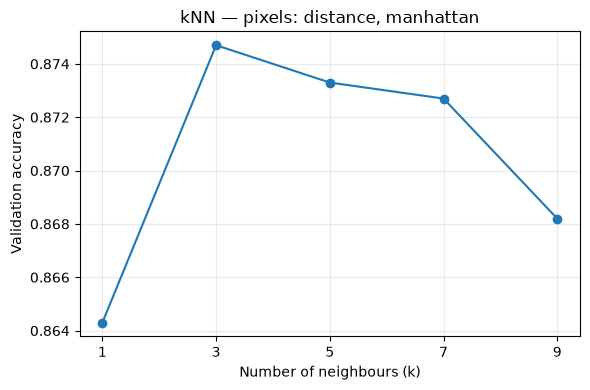

saved results/figures/linear_knn_val_curve_hog.png


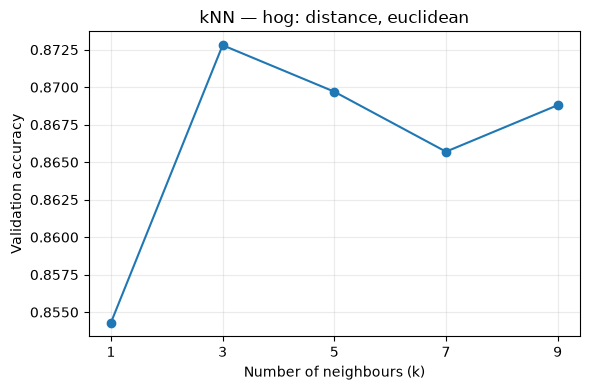

In [6]:
for kind in ("pixels", "hog"):
    result = validation[f"knn_{kind}"]
    best = result["best_params"]
    rows = [row for row in result["rows"]
            if row["params"]["weights"] == best["weights"]
            and row["params"]["metric"] == best["metric"]]
    rows = sorted(rows, key=lambda row: row["params"]["n_neighbors"])
    fig, ax = plt.subplots(figsize=(6, 4))
    ax.plot([row["params"]["n_neighbors"] for row in rows], [row["val_acc"] for row in rows], "o-")
    ax.set(xlabel="Number of neighbours (k)", ylabel="Validation accuracy",
           title=f"kNN — {kind}: {best['weights']}, {best['metric']}")
    ax.set_xticks(KNN_GRID["n_neighbors"])
    ax.grid(alpha=0.25)
    fig.tight_layout()
    save_fig(fig, f"linear_knn_val_curve_{kind}")
    plt.show()


## kNN final evaluation

⏱ The harness times three predictions and keeps the fastest, so each final evaluation can take several minutes. Chosen parameters come exclusively from validation. Existing results are read without refitting or predicting on test again.

In [7]:
for kind in ("pixels", "hog"):
    experiment = f"knn_{kind}"
    params = validation[experiment]["best_params"]
    path = config.METRICS_DIR / f"{experiment}_test.json"
    if path.exists():
        result = json.loads(path.read_text())
        if result["best_params"] != params:
            raise RuntimeError(f"{experiment}: saved test parameters differ; investigate and log any rerun first.")
    else:
        if config.TEST_LOG_PATH.exists() and experiment in pd.read_csv(config.TEST_LOG_PATH)["experiment"].values:
            raise RuntimeError(f"{experiment}: test is already logged; recover its metrics before continuing.")
        result = final_test_run("knn", make_knn, params, kind)
    test_results[experiment] = result
    print(experiment, "test accuracy:", result["accuracy"])


knn_pixels test accuracy: 0.8611
knn_hog test accuracy: 0.8631


## LR weight maps

⏱ About 15–30 seconds for a pixel LR fit. This refit uses only trainval with the validation-selected C; it makes no test predictions.

Each map reshapes one class's 784 coefficients into 28×28 pixels. Red means a larger **standardised** pixel value increases that class's score; blue decreases it. The common symmetric colour scale lets us compare coefficient magnitudes across classes. These are weights in scaler coordinates, not weights per unit of raw brightness. Scores compete through softmax, so an isolated positive pixel is not a complete explanation of a prediction.

pixel LR refit for coefficient maps (no test evaluation): 23.2s


saved results/figures/linear_logreg_weights.png


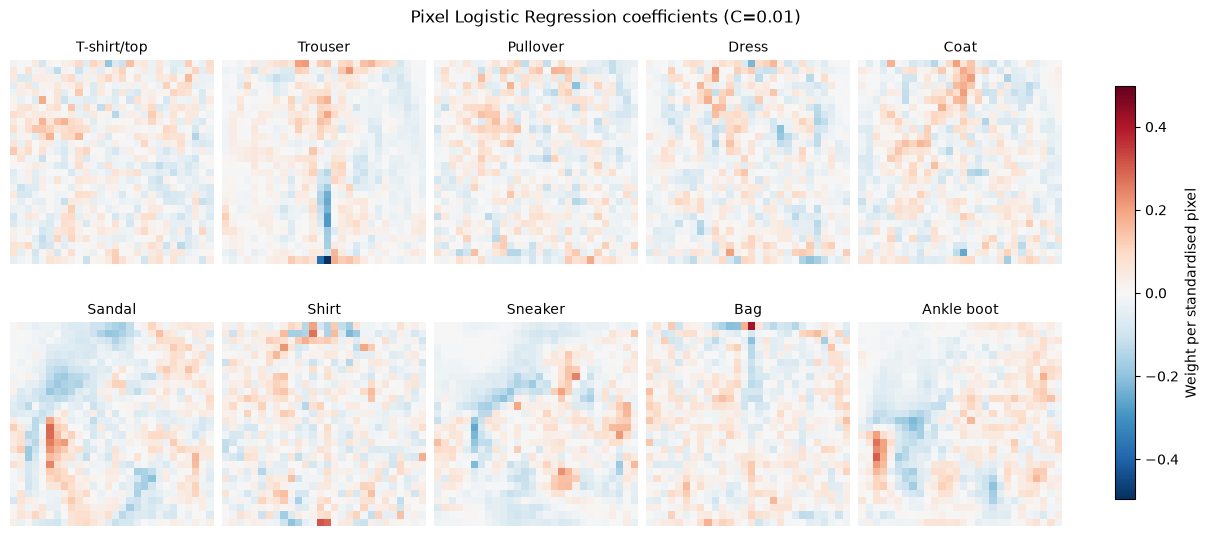

In [8]:
from src.features import get_features, get_labels
from src.utils import Timer

# Refit the validation-selected pixel LR on train+val only for this figure (no test data, D-022).
C = validation["logreg_pixels"]["best_params"]["C"]
model = make_logreg(C)
with Timer("pixel LR refit for coefficient maps (no test evaluation)"):
    model.fit(get_features("pixels", "trainval"), get_labels("trainval"))
classifier = model.named_steps["clf"]
weights = classifier.coef_.reshape(-1, config.IMAGE_SIZE, config.IMAGE_SIZE)
limit = float(np.abs(weights).max())  # one symmetric colour scale for all classes

fig, axes = plt.subplots(2, config.NUM_CLASSES // 2, figsize=(12, 5.5), layout="constrained")
for label, weight, ax in zip(classifier.classes_, weights, axes.flat):
    image = ax.imshow(weight, cmap="RdBu_r", vmin=-limit, vmax=limit)
    ax.set_title(config.CLASS_NAMES[label], fontsize=10)
    ax.axis("off")
fig.colorbar(image, ax=axes.ravel().tolist(), shrink=0.8, label="Weight per standardised pixel")
fig.suptitle(f"Pixel Logistic Regression coefficients (C={C})")
save_fig(fig, "linear_logreg_weights")
plt.show()

## Findings and handoff

**Timing caution:** The two LR JSONs have `timing_comparable=false`: their final runs overlapped validation work. Timing values displayed here are retained raw observations only. Exclude both LR training and inference times from speed comparisons; Phase 05 must emit NaN for these summary columns and omit them from speed plots. Accuracy and other predictive metrics remain usable (D-024).

The Trouser map has a strong negative central strip between the legs; a bright bridge there pushes its score down. The shoe maps emphasise different lower-image regions, consistent with differences in sole and ankle shape. The top-garment maps share broad torso/sleeve regions and have weaker local differences. These are discriminative coefficient patterns, not average images or causal explanations.

Both LR curves prefer the smallest tested C (0.01). HOG LR reaches 89.27% validation accuracy versus 86.42% for pixel LR; its edge representation appears better suited to a linear decision boundary. Because the winner is at a grid boundary, the optimum outside this prescribed grid is unknown; the grid is kept as documented.

Pixel kNN selects three neighbours, Manhattan distance and distance weighting (87.47% validation). HOG kNN selects three neighbours, Euclidean distance and distance weighting (87.28%). HOG's larger feature vector does not guarantee better validation performance for a neighbour-based classifier. A neighbour metric and representation must work together.

The final test results are Dummy 10% for each feature set, LR pixels 84.72%, LR HOG 88.86%, kNN pixels 86.11% and kNN HOG 86.31%. The pixel results are consistent with the approximate sanity targets (~84% LR, ~85–86% kNN); kNN is 0.11 percentage points above 86%. All hyperparameters were fixed from validation before these evaluations. Test numbers are reported here, not used to revise choices.

The coefficient maps show spatial patterns that distinguish garment outlines, but they remain linear templates. Shirt, Coat, Pullover and T-shirt have similar torso/sleeve layouts, as noted in the train-only EDA; overlapping patterns make these plausible difficult cases. Detailed confusion analysis and cross-model comparison plots belong to Phase 05.

Phase 04 should use the same fixed split, chosen HOG settings and harness. The six Phase 03 test evaluations are already complete: load their JSONs rather than evaluating them again. Keep scaling inside each estimator's Pipeline, and use the documented tuning subset for slow SVM models.

In [9]:
phase_results = pd.DataFrame([
    {"experiment": experiment, "params": validation[experiment]["best_params"],
     "val_acc": validation[experiment]["best_val_acc"], "test_acc": result["accuracy"],
     "macro_f1": result["macro_f1"], "fit_s": result["train_time_s"],
     "inference_ms_per_1000": result["inference_ms_per_1000"],
     "model_size_bytes": result["model_size_bytes"]}
    for experiment, result in test_results.items()
])
display(phase_results)
audit = pd.read_csv(config.TEST_LOG_PATH)
counts = audit[audit.experiment.isin(test_results)].experiment.value_counts()
assert len(counts) == len(test_results) == 6 and (counts == 1).all()
print("Phase 03 audit: six experiments, exactly one recorded test run each.")


,experiment,params,val_acc,test_acc,macro_f1,fit_s,inference_ms_per_1000,model_size_bytes
0,dummy_pixels,{},0.1000,0.1000,0.0182,0.00,0.00,709
1,dummy_hog,{},0.1000,0.1000,0.0182,0.16,0.01,709
2,logreg_pixels,{'C': 0.01},0.8642,0.8472,0.8464,30.38,1.05,51396
3,logreg_hog,{'C': 0.01},0.8927,0.8886,0.8885,45.76,2.29,111821
4,knn_pixels,"{'metric': 'manhattan', 'n_neighbors': 3, 'wei...",0.8747,0.8611,0.8614,0.49,6926.61,188659981
5,knn_hog,"{'metric': 'euclidean', 'n_neighbors': 3, 'wei...",0.8728,0.8631,0.8623,1.29,731.13,415242637


Phase 03 audit: six experiments, exactly one recorded test run each.
